# Thí nghiệm 4: Xác minh TinyCAE INT8 trên ESP32

## Mục tiêu

Thí nghiệm đối chiếu latent do encoder INT8 trên ESP32 tạo ra với golden vectors từ PC. Giao tiếp sử dụng UART 115.200 baud và CRC-32. Ngoài độ chính xác số học, thí nghiệm đo thời gian `Invoke()`, tác động của sai khác kernel lên PSNR/SSIM và trạng thái bộ nhớ sau chuỗi inference.

## Điều kiện thiết bị

Firmware `esp32_codec` phải được flash thành công và log khởi động phải xác nhận `TinyCAE ready`. Cổng COM5 chỉ được truy cập bởi một tiến trình tại một thời điểm; ESP-IDF Monitor không hoạt động trong thời gian thu thập dữ liệu bằng notebook.

## 1. Cấu hình phép đo

Phép đo sử dụng cùng 20 ảnh, golden latent, decoder và model manifest của các thí nghiệm trước. Header phản hồi UART có dạng `LATENT <size> <crc32> <time_us>`.

In [7]:
from pathlib import Path
import csv
import io
import re
import time
import zlib

import matplotlib.pyplot as plt
import numpy as np
import serial
import tensorflow as tf
from PIL import Image

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PORT = 'COM5'
BAUD = 115_200
RAW_BYTES = 3072
LATENT_BYTES = 1024
HARDWARE_DIR = PROJECT_ROOT / 'data' / 'processed' / 'hardware_test'
MANIFEST_PATH = HARDWARE_DIR / 'manifest.csv'
GOLDEN_LATENT_DIR = PROJECT_ROOT / 'bitstreams' / 'tinycae' / 'golden' / 'latent_int8'
DECODER_PATH = PROJECT_ROOT / 'models' / 'tinycae' / 'notebook_baseline' / 'decoder.keras'
MODEL_MANIFEST_PATH = PROJECT_ROOT / 'manifests' / 'model_manifest.json'
RESULTS_PATH = PROJECT_ROOT / 'results' / 'tinycae_esp32_20.csv'
HEADER_PATTERN = re.compile(r'^LATENT (?P<size>\d+) (?P<crc>[0-9A-Fa-f]{8}) (?P<time_us>\d+)$')

with MANIFEST_PATH.open(newline='', encoding='utf-8') as stream:
    records = list(csv.DictReader(stream))
assert len(records) == 20
print('Ảnh kiểm thử:', len(records))
print('Cổng:', PORT, BAUD)

Ảnh kiểm thử: 20
Cổng: COM5 115200


## 2. Giao thức truyền nhận UART

Máy tính gửi lệnh `TINYCAE`, chờ phản hồi `READY 3072`, truyền ảnh RGB888 và nhận header latent cùng 1.024 byte dữ liệu. Hàm đọc bỏ qua log khởi động, áp dụng timeout, kiểm tra kích thước và xác minh CRC-32 trước khi chấp nhận mẫu.

In [8]:
def wait_for_line(device, predicate, timeout=15.0):
    deadline = time.monotonic() + timeout
    last_line = ''
    while time.monotonic() < deadline:
        raw = device.readline()
        if not raw:
            continue
        line = raw.decode('utf-8', errors='replace').strip()
        if not line:
            continue
        last_line = line
        if line.startswith('ERROR ') or predicate(line):
            return line
    raise TimeoutError(f'Hết thời gian; dòng cuối={last_line!r}')

def read_exact(device, size, timeout=15.0):
    data = bytearray()
    deadline = time.monotonic() + timeout
    while len(data) < size and time.monotonic() < deadline:
        chunk = device.read(size - len(data))
        if chunk:
            data.extend(chunk)
    if len(data) != size:
        raise TimeoutError(f'Cần {size} byte, nhận {len(data)} byte')
    return bytes(data)

def request_latent(device, raw_rgb):
    assert len(raw_rgb) == RAW_BYTES
    device.write(b'TINYCAE\r\n')
    device.flush()
    ready = wait_for_line(device, lambda line: line == f'READY {RAW_BYTES}')
    if ready != f'READY {RAW_BYTES}':
        raise RuntimeError(f'Phản hồi READY sai: {ready}')
    device.write(raw_rgb)
    device.flush()
    header = wait_for_line(device, lambda line: HEADER_PATTERN.fullmatch(line) is not None)
    match = HEADER_PATTERN.fullmatch(header)
    if match is None:
        raise RuntimeError(f'Header sai: {header}')
    size = int(match.group('size'))
    expected_crc = int(match.group('crc'), 16)
    elapsed_us = int(match.group('time_us'))
    if size != LATENT_BYTES:
        raise RuntimeError(f'Latent sai kích thước: {size}')
    latent = read_exact(device, size)
    actual_crc = zlib.crc32(latent) & 0xFFFFFFFF
    if actual_crc != expected_crc:
        raise RuntimeError(f'CRC sai: ESP32={expected_crc:08X}, PC={actual_crc:08X}')
    return latent, actual_crc, elapsed_us

## 3. Kiểm thử đơn mẫu

Mẫu đầu tiên được sử dụng để xác minh toàn bộ giao thức trước phép đo hàng loạt. Latent ESP32 và golden latent được so sánh theo từng phần tử INT8. Kết quả ghi số phần tử khác nhau, độ lệch tuyệt đối cực đại và phân bố sai khác. Sai khác nhỏ có thể phát sinh do quy tắc làm tròn giữa kernel TFLite tham chiếu và ESP-NN tối ưu.

In [9]:
record = records[0]
image_id = record['image_id']
raw_rgb = (HARDWARE_DIR / 'raw' / f'{image_id}.rgb').read_bytes()
golden_latent = (GOLDEN_LATENT_DIR / f'{image_id}.int8').read_bytes()

with serial.Serial(PORT, BAUD, timeout=0.25) as device:
    device.dtr = False
    device.rts = False
    time.sleep(4.0)
    device.reset_input_buffer()
    esp32_latent, crc32, elapsed_us = request_latent(device, raw_rgb)

esp32_values = np.frombuffer(esp32_latent, dtype=np.int8)
golden_values = np.frombuffer(golden_latent, dtype=np.int8)
delta = esp32_values.astype(np.int16) - golden_values.astype(np.int16)
different = np.flatnonzero(delta != 0)
max_abs_delta = int(np.max(np.abs(delta)))
esp32_output_dir = PROJECT_ROOT / 'bitstreams' / 'tinycae' / 'esp32' / 'latent_int8'
esp32_output_dir.mkdir(parents=True, exist_ok=True)
(esp32_output_dir / f'{image_id}.int8').write_bytes(esp32_latent)
print('Image:', image_id, record['class_name'])
print(f'CRC32: {crc32:08X}')
print('ESP32 invoke time:', elapsed_us, 'us')
print('Different latent bytes:', len(different), '/', LATENT_BYTES)
print('Maximum absolute delta:', max_abs_delta)
print('Delta distribution:', dict(zip(*np.unique(delta, return_counts=True))))
assert max_abs_delta <= 1, f'FAIL: độ lệch INT8 lớn nhất là {max_abs_delta}'
if len(different) == 0:
    print('PASS EXACT: latent ESP32 khớp tuyệt đối golden latent PC.')
else:
    print('PASS TOLERANCE: mọi sai khác chỉ ở mức ±1 LSB; sẽ đánh giá ảnh tái tạo tiếp theo.')

Image: cifar10_test_01789 airplane
CRC32: 068DD0DC
ESP32 invoke time: 61726 us
Different latent bytes: 36 / 1024
Maximum absolute delta: 1
Delta distribution: {np.int16(-1): np.int64(17), np.int16(0): np.int64(988), np.int16(1): np.int64(19)}
PASS TOLERANCE: mọi sai khác chỉ ở mức ±1 LSB; sẽ đánh giá ảnh tái tạo tiếp theo.


## 4. Tái tạo ảnh từ latent ESP32

Latent ESP32 được giải lượng tử bằng output scale và zero point trong model manifest, sau đó đưa qua cùng decoder FP32. PSNR, SSIM và ảnh minh họa xác nhận tính hợp lệ của pipeline phần cứng–phần mềm.

PSNR=32.3797 dB, SSIM=0.978023


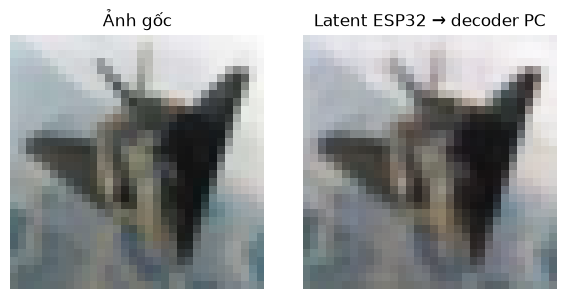

In [10]:
model_manifest = __import__('json').loads(MODEL_MANIFEST_PATH.read_text(encoding='utf-8'))
output_scale = model_manifest['output_scale']
output_zero_point = model_manifest['output_zero_point']
decoder = tf.keras.models.load_model(DECODER_PATH, compile=False)
latent_int8 = np.frombuffer(esp32_latent, dtype=np.int8).reshape(1, 8, 8, 16)
latent_float = (latent_int8.astype(np.float32) - output_zero_point) * output_scale
reconstruction = decoder.predict(latent_float, verbose=0)[0]
reference = np.frombuffer(raw_rgb, dtype=np.uint8).reshape(32, 32, 3).astype(np.float32) / 255.0
psnr = float(tf.image.psnr(reference, reconstruction, max_val=1.0).numpy())
ssim = float(tf.image.ssim(reference, reconstruction, max_val=1.0).numpy())
print(f'PSNR={psnr:.4f} dB, SSIM={ssim:.6f}')

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(reference)
axes[0].set_title('Ảnh gốc')
axes[1].imshow(np.clip(reconstruction, 0, 1))
axes[1].set_title('Latent ESP32 → decoder PC')
for axis in axes:
    axis.axis('off')
plt.tight_layout()

## 5. Đánh giá trên 20 ảnh hardware test

Cổng UART được mở một lần cho toàn bộ tập nhằm tránh reset giữa các mẫu. Với mỗi ảnh, phép đo lưu CRC, thời gian `Invoke()`, số phần tử latent khác nhau, độ lệch cực đại và trạng thái. Dung sai số học tối đa 2 LSB được báo riêng với trường `PASS_TOLERANCE`; trường `PASS_EXACT` chỉ áp dụng khi latent bit-exact. Sau mẫu cuối, lệnh `STATUS` thu thập heap nội và PSRAM.

In [11]:
NUMERIC_TOLERANCE_LSB = 2
esp32_output_dir = PROJECT_ROOT / 'bitstreams' / 'tinycae' / 'esp32' / 'latent_int8'
esp32_output_dir.mkdir(parents=True, exist_ok=True)
rows = []
with serial.Serial(PORT, BAUD, timeout=0.25) as device:
    device.dtr = False
    device.rts = False
    time.sleep(4.0)
    device.reset_input_buffer()
    for number, record in enumerate(records, start=1):
        image_id = record['image_id']
        raw_rgb = (HARDWARE_DIR / 'raw' / f'{image_id}.rgb').read_bytes()
        golden = (GOLDEN_LATENT_DIR / f'{image_id}.int8').read_bytes()
        latent, crc32, elapsed_us = request_latent(device, raw_rgb)
        (esp32_output_dir / f'{image_id}.int8').write_bytes(latent)
        latent_values = np.frombuffer(latent, dtype=np.int8).astype(np.int16)
        golden_values = np.frombuffer(golden, dtype=np.int8).astype(np.int16)
        delta = latent_values - golden_values
        difference_count = int(np.count_nonzero(delta))
        max_abs_delta = int(np.max(np.abs(delta)))
        rows.append({
            'image_id': image_id,
            'class_name': record['class_name'],
            'latent_bytes': len(latent),
            'crc32': f'{crc32:08X}',
            'invoke_time_us': elapsed_us,
            'different_bytes': difference_count,
            'max_abs_delta': max_abs_delta,
            'exact_match': difference_count == 0,
            'status': ('PASS_EXACT' if difference_count == 0 else 'PASS_TOLERANCE' if max_abs_delta <= NUMERIC_TOLERANCE_LSB else 'FAIL'),
        })
        print(f"[{number:02d}/20] {image_id}: {rows[-1]['status']}, {elapsed_us} us, diff={difference_count}, max_delta={max_abs_delta}")
    device.write(b'STATUS\r\n')
    device.flush()
    memory_status = wait_for_line(device, lambda line: line.startswith('MEM '))
    print(memory_status)

RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)
with RESULTS_PATH.open('w', newline='', encoding='utf-8') as stream:
    writer = csv.DictWriter(stream, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)

passed = sum(row['status'].startswith('PASS') for row in rows)
mean_time_us = np.mean([row['invoke_time_us'] for row in rows])
print(f'PASS: {passed}/20')
print(f'Thời gian Invoke trung bình: {mean_time_us:.2f} us')
print('CSV:', RESULTS_PATH)
assert passed == 20, 'Có latent lệch quá dung sai; xem CSV trước khi tiếp tục'

[01/20] cifar10_test_01789: PASS_TOLERANCE, 61726 us, diff=36, max_delta=1
[02/20] cifar10_test_08563: PASS_TOLERANCE, 60668 us, diff=39, max_delta=1
[03/20] cifar10_test_03745: PASS_TOLERANCE, 60654 us, diff=21, max_delta=1
[04/20] cifar10_test_06493: PASS_TOLERANCE, 60656 us, diff=13, max_delta=1
[05/20] cifar10_test_00776: PASS_TOLERANCE, 60653 us, diff=11, max_delta=1
[06/20] cifar10_test_03534: PASS_TOLERANCE, 60651 us, diff=26, max_delta=1
[07/20] cifar10_test_03607: PASS_TOLERANCE, 60655 us, diff=14, max_delta=1
[08/20] cifar10_test_08241: PASS_TOLERANCE, 60649 us, diff=11, max_delta=2
[09/20] cifar10_test_06822: PASS_TOLERANCE, 60654 us, diff=23, max_delta=1
[10/20] cifar10_test_08944: PASS_TOLERANCE, 60651 us, diff=20, max_delta=1
[11/20] cifar10_test_01922: PASS_TOLERANCE, 60665 us, diff=39, max_delta=1
[12/20] cifar10_test_08458: PASS_TOLERANCE, 60656 us, diff=32, max_delta=1
[13/20] cifar10_test_00891: PASS_TOLERANCE, 60658 us, diff=35, max_delta=2
[14/20] cifar10_test_0286

## 6. Phân tích ảnh hưởng của sai khác kernel

Golden latent và latent ESP32 được giải lượng tử bằng cùng tham số và đưa qua cùng decoder. Chênh lệch PSNR, SSIM, sai khác tuyệt đối trung bình và sai khác cực đại giữa hai ảnh tái tạo định lượng tác động thực tế của sai số 1–2 LSB.

In [12]:
import json
model_manifest = json.loads(MODEL_MANIFEST_PATH.read_text(encoding='utf-8'))
output_scale = model_manifest['output_scale']
output_zero_point = model_manifest['output_zero_point']
decoder = tf.keras.models.load_model(DECODER_PATH, compile=False)

references = []
golden_latents = []
esp32_latents = []
for record in records:
    image_id = record['image_id']
    raw = (HARDWARE_DIR / 'raw' / f'{image_id}.rgb').read_bytes()
    references.append(np.frombuffer(raw, dtype=np.uint8).reshape(32, 32, 3).astype(np.float32) / 255.0)
    golden_latents.append(np.frombuffer((GOLDEN_LATENT_DIR / f'{image_id}.int8').read_bytes(), dtype=np.int8).reshape(8, 8, 16))
    esp32_latents.append(np.frombuffer((esp32_output_dir / f'{image_id}.int8').read_bytes(), dtype=np.int8).reshape(8, 8, 16))
references = np.asarray(references, dtype=np.float32)
golden_latents = np.asarray(golden_latents, dtype=np.int8)
esp32_latents = np.asarray(esp32_latents, dtype=np.int8)
golden_float = (golden_latents.astype(np.float32) - output_zero_point) * output_scale
esp32_float = (esp32_latents.astype(np.float32) - output_zero_point) * output_scale
golden_recon = decoder.predict(golden_float, batch_size=20, verbose=0)
esp32_recon = decoder.predict(esp32_float, batch_size=20, verbose=0)
golden_psnr = tf.image.psnr(references, golden_recon, max_val=1.0).numpy()
esp32_psnr = tf.image.psnr(references, esp32_recon, max_val=1.0).numpy()
golden_ssim = tf.image.ssim(references, golden_recon, max_val=1.0).numpy()
esp32_ssim = tf.image.ssim(references, esp32_recon, max_val=1.0).numpy()
recon_abs_delta = np.abs(esp32_recon - golden_recon)
print(f'Golden PSNR: {golden_psnr.mean():.6f} dB | ESP32 PSNR: {esp32_psnr.mean():.6f} dB')
print(f'Delta PSNR: {(esp32_psnr - golden_psnr).mean():.6f} dB')
print(f'Golden SSIM: {golden_ssim.mean():.8f} | ESP32 SSIM: {esp32_ssim.mean():.8f}')
print(f'Delta SSIM: {(esp32_ssim - golden_ssim).mean():.8f}')
print(f'Reconstruction mean absolute delta: {recon_abs_delta.mean():.8f}')
print(f'Reconstruction maximum absolute delta: {recon_abs_delta.max():.8f}')
for index, row in enumerate(rows):
    row['golden_psnr_db'] = float(golden_psnr[index])
    row['esp32_psnr_db'] = float(esp32_psnr[index])
    row['delta_psnr_db'] = float(esp32_psnr[index] - golden_psnr[index])
    row['golden_ssim'] = float(golden_ssim[index])
    row['esp32_ssim'] = float(esp32_ssim[index])
    row['delta_ssim'] = float(esp32_ssim[index] - golden_ssim[index])
with RESULTS_PATH.open('w', newline='', encoding='utf-8') as stream:
    writer = csv.DictWriter(stream, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)

Golden PSNR: 30.555948 dB | ESP32 PSNR: 30.554998 dB
Delta PSNR: -0.000951 dB
Golden SSIM: 0.96797591 | ESP32 SSIM: 0.96793222
Delta SSIM: -0.00004374
Reconstruction mean absolute delta: 0.00091629
Reconstruction maximum absolute delta: 0.02590036


## 7. Tiêu chí hoàn thành

- 20/20 ảnh đúng CRC và đủ 1.024 byte.
- Báo riêng số ảnh khớp tuyệt đối và số ảnh đạt dung sai tối đa 2 LSB.
- Chênh lệch PSNR/SSIM do kernel PC–ESP32 phải được đo và ghi lại.
- CRC của mọi latent hợp lệ.
- Có thời gian `Invoke()` trung bình trên ESP32.

Việc thỏa các tiêu chí trên xác nhận encoder TinyCAE INT8 đã được triển khai đúng trên ESP32 trong phạm vi dung sai số học giữa hai họ kernel.